# EDA временного ряда продаж: товар **85099B — JUMBO BAG RED RETROSPOT**

**Данные:** [Online Retail (UCI)](https://archive.ics.uci.edu/dataset/352/online+retail), транзакции британского онлайн-ритейлера подарочных товаров (в основном оптовые покупатели), период 01.12.2010–09.12.2011.

**План:**
1. Загрузка и очистка данных, выбор товара.
2. Построение рядов: дневная, недельная и месячная агрегация.
3. Качество данных: пропуски и выбросы.
4. Визуальный и описательный анализ, дополнительные характеристики.
5. Декомпозиция и сезонность.
6. Стационарность и преобразование к стационарному виду.
7. Выводы.

Все методы реализованы функциями в модуле [`src/ts_analysis.py`](src/ts_analysis.py). В ноутбуке только их вызовы и интерпретация.

In [1]:
import sys
import warnings
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "src")
import ts_analysis as ta

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12})

STOCK_CODE = "85099B"
PRODUCT = "JUMBO BAG RED RETROSPOT"

## 1. Загрузка, структура и очистка данных

In [2]:
df_raw = ta.load_online_retail("data")   # при отсутствии файла скачает его с UCI
print(df_raw.shape)
print("Период:", df_raw["InvoiceDate"].min(), "—", df_raw["InvoiceDate"].max())
ta.describe_raw_data(df_raw)

(541909, 8)
Период: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


,dtype,n_missing,share_missing,n_unique,example
InvoiceNo,str,0,0.0000,25900,536365
StockCode,str,0,0.0000,3958,85123A
Description,object,1454,0.0027,4223,WHITE HANGING HEART T-LIGHT HOLDER
Quantity,int64,0,0.0000,722,6
InvoiceDate,datetime64[us],0,0.0000,23260,2010-12-01 08:26:00
UnitPrice,float64,0,0.0000,1630,2.55
CustomerID,float64,135080,0.2493,4372,17850.0
Country,str,0,0.0000,38,United Kingdom


Для построения ряда нужны поля:
- `StockCode`: отбор товара;
- `InvoiceDate`: дата и время продажи;
- `Quantity`: показатель продаж, количество проданных штук;
- `UnitPrice`: цена, для выручки и анализа цены;
- `InvoiceNo`: номер счёта (по префиксу `C` определяются отмены).

Пропуски в `CustomerID` (~25 %) и `Description` на построение ряда продаж не влияют.

**Показатель продаж:** суммарное количество проданных штук (`Quantity`). Отмены, нулевые цены и складские корректировки удаляются: они не отражают спрос в момент продажи. Отмены по товару отдельно вынесены в характеристики.

In [3]:
df, cleaning_report = ta.clean_transactions(df_raw)
cleaning_report

,rows,share
Отмены (InvoiceNo = C...),9288,0.0171
Quantity <= 0 (не отмены),1336,0.0025
UnitPrice <= 0,1181,0.0022
Полные дубликаты,5226,0.0096


### Выбор товара
Товар 85123A разбирался на занятии и исключён. Выбираем товар с «плотным» рядом, то есть с продажами почти в каждый рабочий день, чтобы дневная агрегация была информативной.

In [4]:
ta.top_products(df, 10)

,description,days_with_sales,n_invoices,total_qty,total_revenue
StockCode,,,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,305,2265,37933,106415.0
22423,REGENCY CAKESTAND 3 TIER,301,1988,13851,174157.0
84879,ASSORTED COLOUR BIRD ORNAMENT,300,1455,36362,58928.0
85099B,JUMBO BAG RED RETROSPOT,300,2089,48371,94160.0
21212,PACK OF 72 RETROSPOT CAKE CASES,298,1320,36396,21246.0
20725,LUNCH BAG RED RETROSPOT,298,1565,19432,35862.0
22457,NATURAL SLATE HEART CHALKBOARD,297,1249,9119,27992.0
22960,JAM MAKING SET WITH JARS,295,1132,8695,37082.0
22197,POPCORN HOLDER,294,1392,56898,51334.0


**85099B JUMBO BAG RED RETROSPOT** продаётся в 300 рабочих днях из 305. По объёму в штуках это лидер среди самых регулярных товаров (≈48 тыс. шт., ≈2 100 счетов). Выбираем его.

In [5]:
ta.cancellations_for_product(df_raw, STOCK_CODE)

Продано, шт.          48478.0
Отменено, шт.          1115.0
Доля отмен, %             2.3
Число счетов-отмен       43.0
dtype: float64

Отмены по товару составляют около 2 % проданного объёма. Это мало, поэтому решение исключить их из ряда на результат практически не влияет.

## 2. Построение временных рядов (день / неделя / месяц)

Нужно различать два вида отсутствия продаж:
- **магазин не работал**: в этот день во всём датасете нет ни одного счёта (субботы, рождественские каникулы, банковские выходные). Наблюдения не существует, поэтому ставим `NaN`, а не 0;
- **магазин работал, но товар не купили**: это реальный нулевой спрос, ставим `0`.

Недели (Пн–Вс) и месяцы агрегируются из дневного ряда. Для каждого периода считается число рабочих дней и флаг **неполного периода** (первая неделя декабря 2010 и последние неделя и месяц декабря 2011, данные до 09.12.2011).

In [6]:
frames = ta.build_all_series(df, STOCK_CODE)
frames["D"].head(8)

,quantity,revenue,n_invoices,n_customers,store_open,avg_price
date,,,,,,
2010-12-01,556.0,938.72,12.0,8.0,True,1.688345
2010-12-02,48.0,93.60,5.0,5.0,True,1.950000
2010-12-03,49.0,109.11,7.0,3.0,True,2.226735
2010-12-04,NaN,NaN,NaN,NaN,False,NaN
2010-12-05,39.0,76.05,6.0,6.0,True,1.950000
2010-12-06,157.0,294.23,10.0,8.0,True,1.874076
2010-12-07,343.0,619.53,10.0,5.0,True,1.806210
2010-12-08,205.0,378.79,9.0,8.0,True,1.847756


In [7]:
frames['W'].head(6)

,quantity,revenue,n_invoices,n_work_days,avg_price,qty_per_work_day,is_partial
period,,,,,,,
2010-12-05,692.0,1217.48,30.0,4,1.759364,173.000000,True
2010-12-12,852.0,1576.32,42.0,6,1.850141,142.000000,False
2010-12-19,427.0,863.67,34.0,6,2.022646,71.166667,False
2010-12-26,180.0,361.68,13.0,4,2.009333,45.000000,False
2011-01-02,0.0,0.00,0.0,0,NaN,NaN,False
2011-01-09,1374.0,2328.34,27.0,5,1.694571,274.800000,False


In [8]:
frames['M']

,quantity,revenue,n_invoices,n_work_days,avg_price,qty_per_work_day,is_partial
period,,,,,,,
2010-12-01,2151.0,4019.15,119.0,20,1.868503,107.550000,False
2011-01-01,2747.0,5047.65,119.0,24,1.837514,114.458333,False
2011-02-01,3080.0,5617.24,123.0,24,1.823779,128.333333,False
2011-03-01,5280.0,10118.38,171.0,27,1.916360,195.555556,False
2011-04-01,2456.0,4878.08,122.0,21,1.986189,116.952381,False
2011-05-01,3621.0,7122.73,186.0,25,1.967062,144.840000,False
2011-06-01,3681.0,7247.98,181.0,26,1.969025,141.576923,False
2011-07-01,3129.0,6253.87,184.0,26,1.998680,120.346154,False
2011-08-01,5402.0,10622.56,177.0,26,1.966412,207.769231,False


## 3. Качество данных: пропуски и выбросы
### 3.1. Ряд до обработки

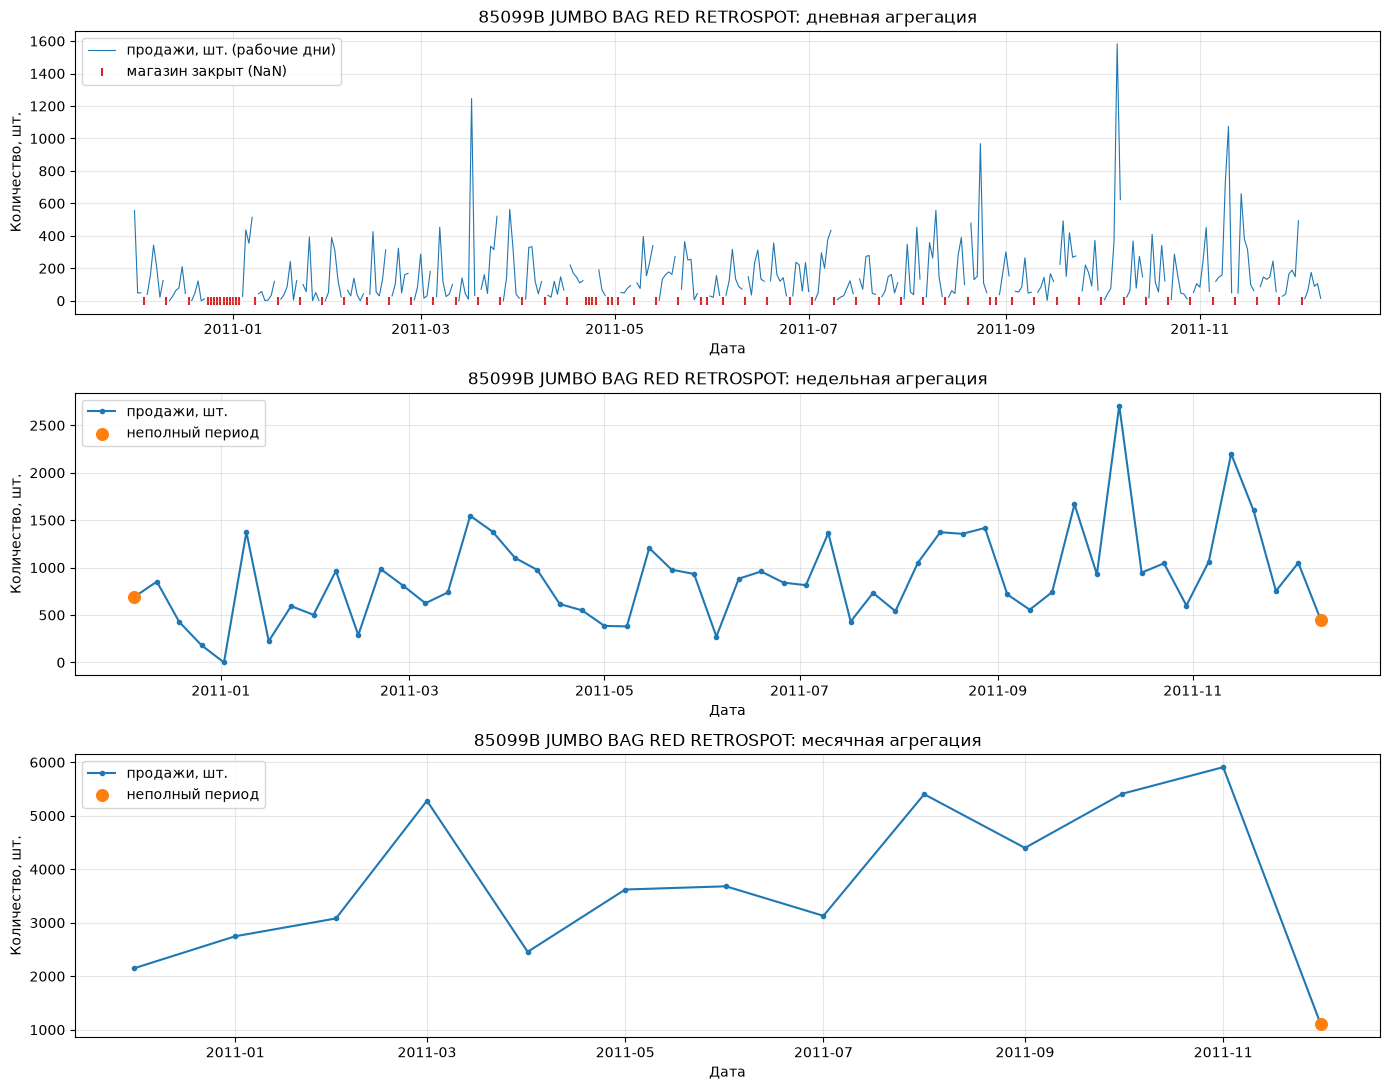

In [9]:
ta.plot_raw_aggregations(frames, f'{STOCK_CODE} {PRODUCT}')

### 3.2. Пропуски

In [10]:
ta.missing_report(frames)

,всего периодов,магазин закрыт (NaN),рабочих периодов,рабочих периодов без продаж (0),неполных периодов
D,374,69,305,5,0
W,54,1,53,0,2
M,13,0,13,0,1


In [11]:
closed_by_weekday, closed_blocks = ta.closed_days_breakdown(frames["D"])
print("Нерабочие дни по дням недели:")
print(closed_by_weekday.to_string())
print("\nБлоки нерабочих дней помимо обычных суббот:")
closed_blocks

Нерабочие дни по дням недели:
date
Пн     6
Вт     1
Ср     1
Чт     1
Пт     4
Сб    53
Вс     3

Блоки нерабочих дней помимо обычных суббот:


,start,end,days
0,2010-12-24,2011-01-03,11
1,2011-04-22,2011-04-25,4
2,2011-04-29,2011-04-30,2
3,2011-05-02,2011-05-02,1
4,2011-05-30,2011-05-30,1
5,2011-08-29,2011-08-29,1


**Интерпретация пропусков**
- В дневном календаре 374 дня, из них **69 дней магазин не работал**. Это 53 субботы (по субботам магазин не работает весь год), рождественские каникулы 24.12.2010–03.01.2011 и британские банковские выходные: Пасха 22–25.04, королевская свадьба 29.04, 2 и 30 мая, 29 августа. Это **структурные пропуски**: в эти дни не было продаж по всему магазину. Их нельзя заполнять нулями, иначе появятся ложные «провалы» спроса, а недельная периодичность исказится. Для дневного анализа используем **только рабочие дни** (305 наблюдений).
- Рабочих дней без продаж товара всего **5**. Это реальный нулевой спрос, такие значения остаются нулями.
- На недельной частоте одна неделя (27.12.2010–02.01.2011) целиком приходится на каникулы, и наблюдения за неё нет. Две крайние недели и декабрь 2011 неполные (данные заканчиваются 09.12.2011). Их исключаем, иначе они выглядят как резкое падение спроса.
- Обработка (интерполяция) не требуется: после исключения нерабочих и неполных периодов ряды не содержат пропусков.

In [12]:
series = {f: ta.analysis_series(frames, f) for f in ["D", "W", "M"]}
{f: len(s) for f, s in series.items()}

{'D': 305, 'W': 51, 'M': 12}

### 3.3. Выбросы
Используем два метода, которые дополняют друг друга:
- **IQR (правило Тьюки)**: глобальный, ищет значения за пределами Q3 + 1.5·IQR;
- **фильтр Хампеля**: локальный, считает отклонение от скользящей медианы в единицах MAD (|robust z| > 3.5) и устойчив к тренду.

Выбросом считаем наблюдение, которое отметили **оба** метода.

In [13]:
outliers_d = ta.detect_outliers(series["D"], window=15)
outliers_w = ta.detect_outliers(series["W"], window=7)
outliers_m = ta.detect_outliers(series["M"], window=5)
pd.DataFrame({"D": ta.outlier_summary(outliers_d), "W": ta.outlier_summary(outliers_w),
              "M": ta.outlier_summary(outliers_m)})

,D,W,M
наблюдений,305.00,51.00,12.0
IQR,14.00,2.00,0.0
Hampel,23.00,3.00,1.0
оба метода,10.00,1.00,0.0
"доля (оба), %",3.28,1.96,0.0


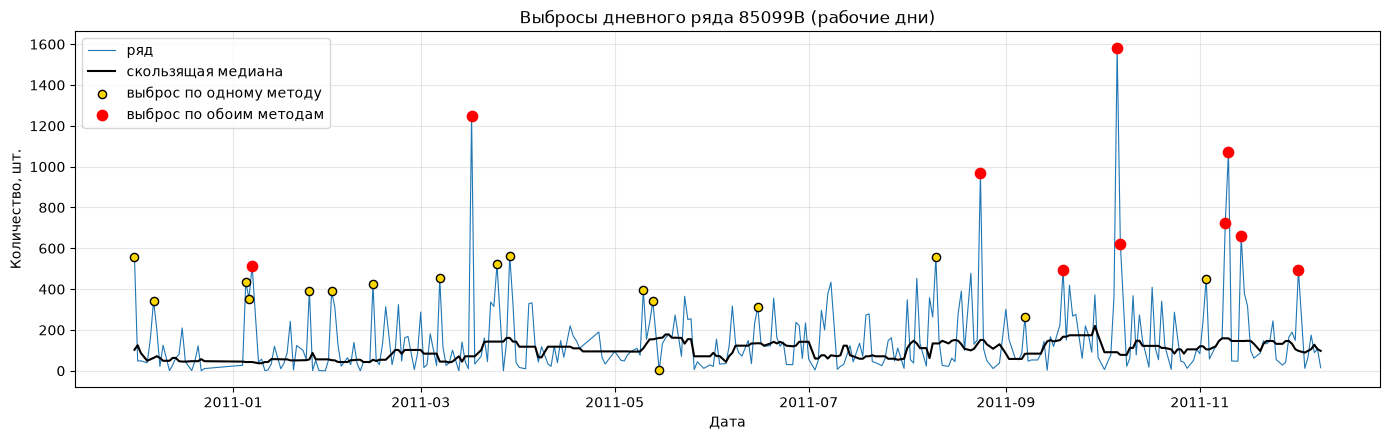

In [14]:
ta.plot_outliers(outliers_d, f'Выбросы дневного ряда {STOCK_CODE} (рабочие дни)')

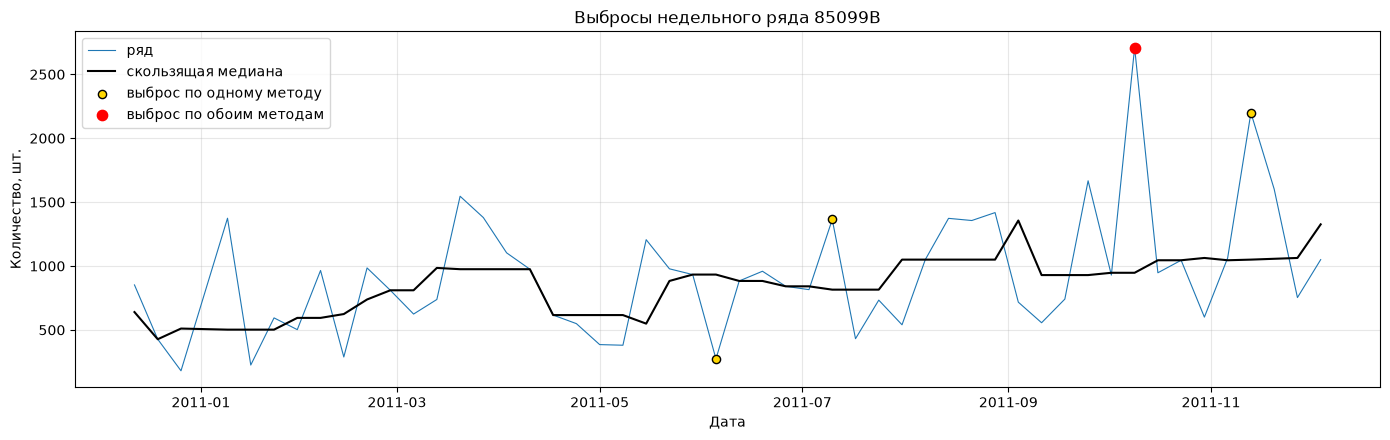

In [15]:
ta.plot_outliers(outliers_w, f'Выбросы недельного ряда {STOCK_CODE}')

In [16]:
ta.explain_outliers(outliers_d, df, STOCK_CODE)

,qty_day,n_invoices,max_single_order,country_of_max,share_of_max_order
Date,,,,,
2011-10-06,1583,16,1000,United Kingdom,0.63
2011-03-17,1246,7,1200,United Kingdom,0.96
2011-11-10,1074,12,1000,United Kingdom,0.93
2011-08-24,968,9,300,United Kingdom,0.31
2011-11-09,725,15,200,United Kingdom,0.28
2011-11-14,660,7,400,United Kingdom,0.61
2011-10-07,623,7,300,United Kingdom,0.48
2011-01-07,514,4,400,United Kingdom,0.78
2011-09-19,493,13,100,Netherlands,0.20


**Интерпретация выбросов и решение**
- Почти все дневные выбросы объясняются **одним-двумя крупными оптовыми заказами** (300–1 200 шт. в одной строке при медиане 10 шт.). Например, 17.03.2011 один заказ на 1 200 шт. дал 96 % дневного объёма. Это не ошибки ввода, а реальная особенность спроса оптового магазина. При агрегации по неделям и месяцам такие пики сглаживаются: на неделях выбросов единицы, на месяцах их нет.
- **Решение: выбросы не удаляем и не корректируем.** Они отражают реальный спрос, и прогнозная модель должна уметь с ними работать. Чтобы ограничить их влияние, дальше используем устойчивые методы: STL с `robust=True` и лог-преобразование `log1p`, которое сжимает большие значения.
- Для сравнения ниже показан вариант с заменой выбросов скользящей медианой. Он сильно снижает дисперсию и эксцесс, но убирает реальную информацию о крупных заказах, поэтому в основном анализе не используется.

In [17]:
winsorized_d = ta.winsorize_outliers(outliers_d)
ta.stats_table({"D исходный": series["D"], "D с заменой выбросов": winsorized_d}).loc[
    ["mean", "std", "max", "CV (std/mean)", "skewness", "kurtosis (excess)"]]

,D исходный,D с заменой выбросов
mean,158.593,134.933
std,187.581,124.602
max,1583.0,563.0
CV (std/mean),1.183,0.923
skewness,3.195,1.253
kurtosis (excess),16.014,0.934


## 4. Визуальный и описательный анализ
### 4.1. Описательные статистики

In [18]:
ta.stats_table(series)

,D,W,M
n,305,51,12
mean,158.593,926.039,3938.833
median,105.0,883.0,3651.0
std,187.581,485.763,1299.5
min,0.0,180.0,2151.0
Q1,43.0,597.0,2996.75
Q3,220.0,1083.0,5310.5
max,1583.0,2709.0,5908.0
CV (std/mean),1.183,0.525,0.33
skewness,3.195,1.235,0.199


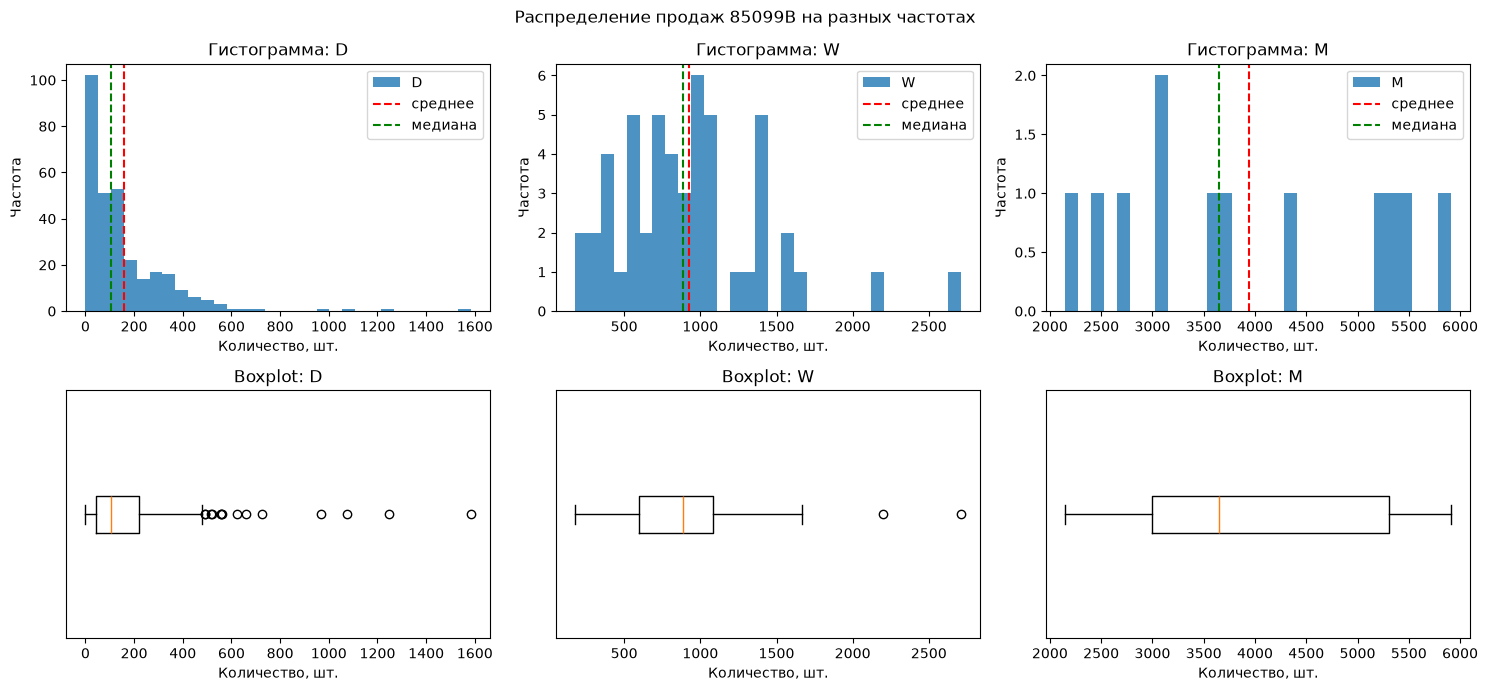

In [19]:
ta.plot_distribution(series, f'Распределение продаж {STOCK_CODE} на разных частотах')

**Интерпретация**
- **День:** в среднем ≈159 шт. в рабочий день при медиане 105. Распределение сильно скошено вправо (асимметрия ≈3.2, эксцесс ≈16) из-за крупных оптовых заказов. CV > 1, по классификации Syntetos–Boylan спрос **erratic**: продажи почти каждый день (ADI ≈ 1), но объём сильно колеблется (CV² ≈ 1.4).
- **Неделя и месяц:** агрегация сглаживает шум. CV падает до ≈0.5 и ≈0.3, распределение становится ближе к симметричному, спрос можно считать **smooth** (регулярным). Для прогнозирования этого товара недельная частота выглядит наиболее удобной: шума заметно меньше, чем у дневной, а наблюдений достаточно (51).

### 4.2. Изменение уровня и разброса во времени

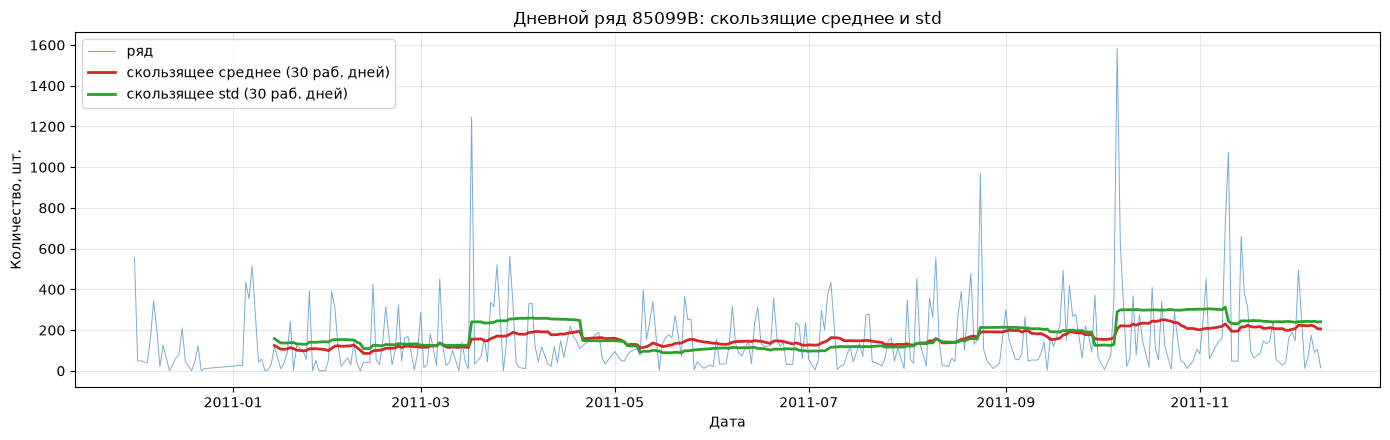

In [20]:
ta.plot_rolling(series['D'], 30, f'Дневной ряд {STOCK_CODE}: скользящие среднее и std', 'раб. дней')

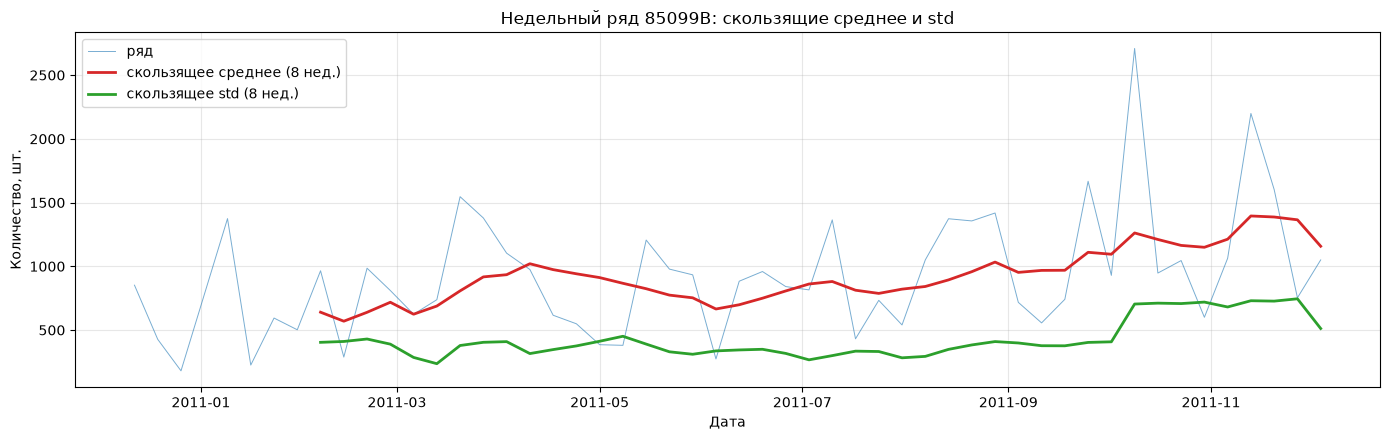

In [21]:
ta.plot_rolling(series['W'], 8, f'Недельный ряд {STOCK_CODE}: скользящие среднее и std', 'нед.')

In [22]:
quarter_table, quarter_tests = ta.level_variance_by_period(series["D"], "QS")
display(quarter_table)
quarter_tests

,n,mean,median,std,CV
2010-10-01,20,107.6,48.5,137.4,1.28
2011-01-01,75,148.1,57.0,197.2,1.33
2011-04-01,72,135.5,120.0,101.6,0.75
2011-07-01,78,165.8,115.0,165.7,1.00
2011-10-01,60,207.1,116.0,272.2,1.31


Kruskal–Wallis p-value (уровень)    0.06039
Levene p-value (дисперсия)          0.10066
corr(mean, std) по периодам         0.83500
dtype: float64

In [23]:
pd.DataFrame({'D': ta.trend_test(series['D']), 'W': ta.trend_test(series['W']), 'M': ta.trend_test(series['M'])})

,D,W,M
n,305.00000,51.00000,12.00000
Kendall tau,0.12500,0.25600,0.69700
Mann–Kendall p-value,0.00115,0.00810,0.00097
наклон OLS за период,0.29000,13.28000,270.05000
OLS p-value,0.01550,0.00309,0.00503
"рост за период, % от среднего",0.19000,1.43000,6.86000


**Интерпретация**
- Скользящее среднее показывает **рост уровня продаж**, особенно с августа 2011. Месячные продажи выросли с ≈2–3 тыс. шт. в начале года до ≈5–6 тыс. шт. в октябре–ноябре. Тесты Манна–Кендалла и OLS подтверждают **значимый положительный тренд** на всех частотах (p < 0.05).
- **Разброс растёт вместе с уровнем:** корреляция среднего и std по кварталам ≈0.8. Это признак мультипликативной структуры, при которой колебания пропорциональны уровню. Поэтому перед декомпозицией и тестами стационарности логично применить лог-преобразование. Формальные тесты по кварталам (Kruskal–Wallis для уровня, Levene для дисперсии) дают p около 0.06–0.10, то есть на дневном шуме различия между кварталами на границе значимости.

### 4.3. Дополнительные характеристики

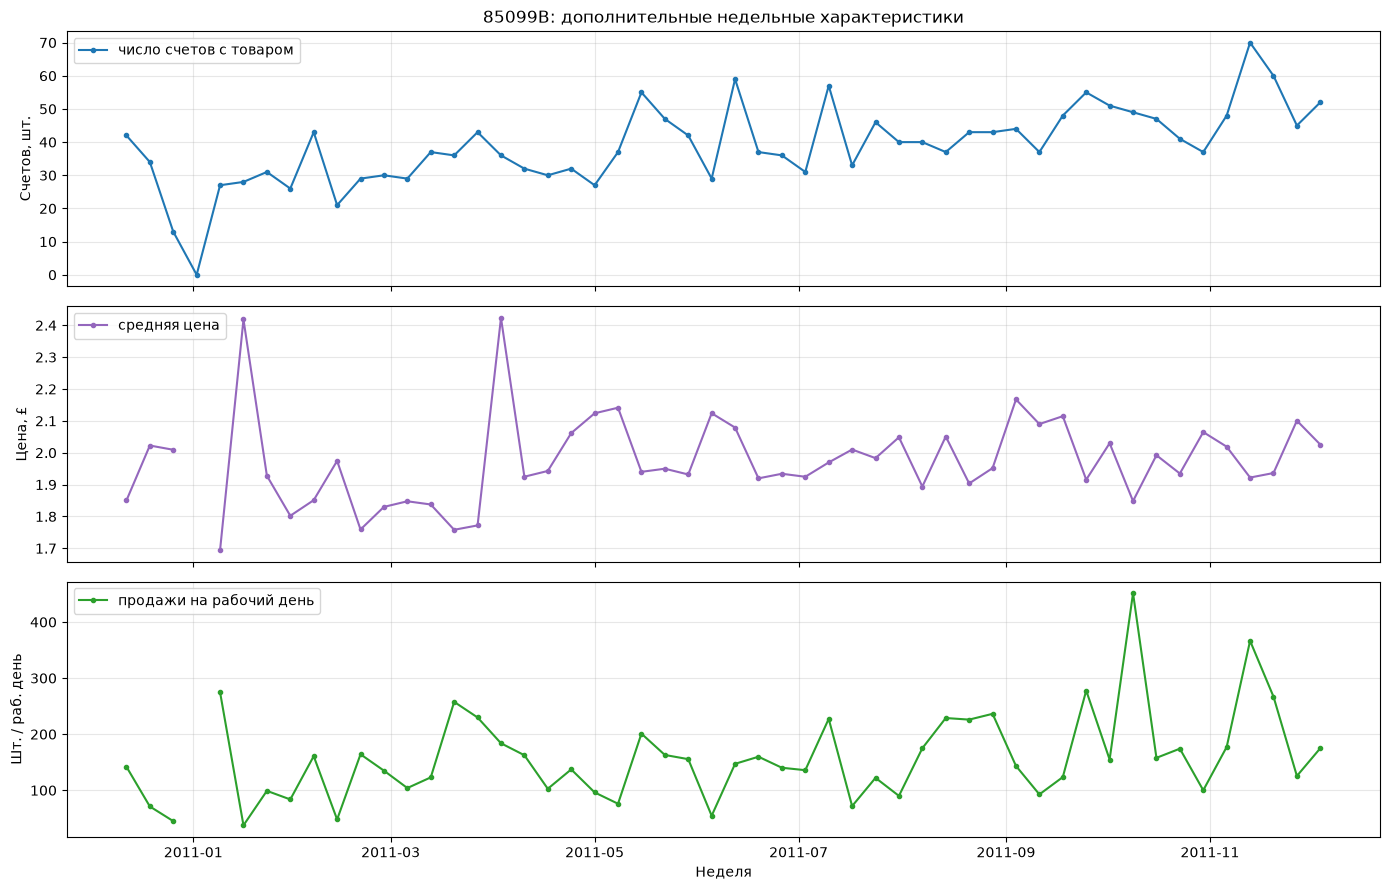

In [24]:
ta.plot_extra_characteristics(frames, f'{STOCK_CODE}: дополнительные недельные характеристики')

In [25]:
display(ta.country_structure(df, STOCK_CODE))
display(ta.order_size_profile(df, STOCK_CODE).to_frame("размер строки заказа, шт."))
ta.price_quantity_relation(frames, "W")

,quantity,"share, %"
Country,,
United Kingdom,44161,91.3
Netherlands,2000,4.1
Germany,522,1.1
France,440,0.9
Channel Islands,250,0.5


,"размер строки заказа, шт."
count,2109.0
mean,22.9
std,59.5
min,1.0
50%,10.0
90%,60.0
99%,200.0
max,1200.0


Spearman rho     -0.46300
p-value           0.00063
мин. ср. цена     1.69000
макс. ср. цена    2.42000
dtype: float64

,count,mean,median,std
Пн,47,164.6,105.0,152.0
Вт,52,178.4,150.5,125.2
Ср,53,189.5,135.0,194.6
Чт,53,219.1,134.0,298.8
Пт,50,137.4,83.0,149.6
Вс,50,56.7,30.0,80.6


Kruskal–Wallis по дням недели: p-value = 5.27e-09


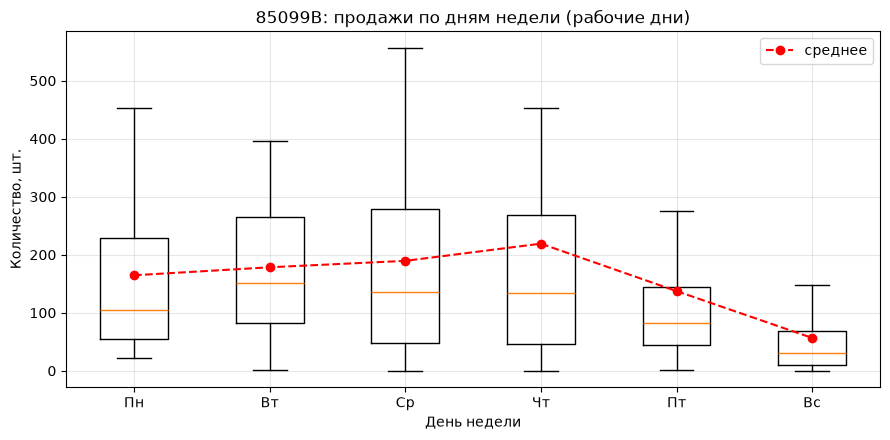

In [26]:
weekday_table, weekday_p = ta.weekday_profile(series["D"])
display(weekday_table)
print(f"Kruskal–Wallis по дням недели: p-value = {weekday_p:.2e}")
ta.plot_weekday_profile(series["D"], f"{STOCK_CODE}: продажи по дням недели (рабочие дни)")

**Интерпретация дополнительных характеристик**
- **Структура покупателей:** около 91 % объёма приходится на Великобританию. Медианный размер строки заказа 10 шт., но в 1 % строк 200 шт. и больше. Это оптовый спрос с «тяжёлым хвостом».
- **Число счетов** с товаром растёт в течение года. Значит, рост продаж обеспечен **расширением числа покупок**, а не только отдельными крупными заказами.
- **Цена:** средняя недельная цена меняется в узком диапазоне (≈1.7–2.4 £) и отрицательно связана с объёмом (ρ Спирмена ≈ −0.46, p < 0.001). Это эффект оптовой скидки: в недели с крупными заказами средняя цена за штуку ниже.
- **День недели:** продажи по воскресеньям в 2.5–4 раза ниже, чем в будни, пик приходится на вторник–четверг. Различие статистически значимо (Kruskal–Wallis, p ≪ 0.001). Это первый аргумент в пользу **недельной сезонности** дневного ряда.

## 5. Декомпозиция и сезонность

**Метод: STL** (Seasonal-Trend decomposition using LOESS, `robust=True`). Он допускает меняющуюся сезонность, устойчив к выбросам и не теряет крайние точки, в отличие от классического `seasonal_decompose`.

Сезонный период выбираем по смыслу каждой частоты:
- **дневной ряд:** недельный цикл. Магазин работает 6 дней в неделю (Вс–Пт), поэтому на ряде рабочих дней период равен **6**. Из-за мультипликативной структуры (п. 4.2) раскладываем `log1p(ряд)`;
- **недельный ряд:** годовой цикл (52 недели) оценить нельзя, наблюдений меньше одного года. Проверяем гипотезу о месячном цикле с периодом **4**;
- **месячный ряд:** 12 точек. Для годовой сезонности нужно минимум 2 полных цикла (24 месяца), поэтому сезонную декомпозицию провести **невозможно**. Анализируем только тренд.

Силу компонент оцениваем по Hyndman & Athanasopoulos: F = max(0, 1 − Var(R)/Var(S+R)). Значения ближе к 1 означают выраженную компоненту, значения ниже ≈0.4 говорят о слабой.

### 5.1. Дневной ряд, период 6 (неделя)

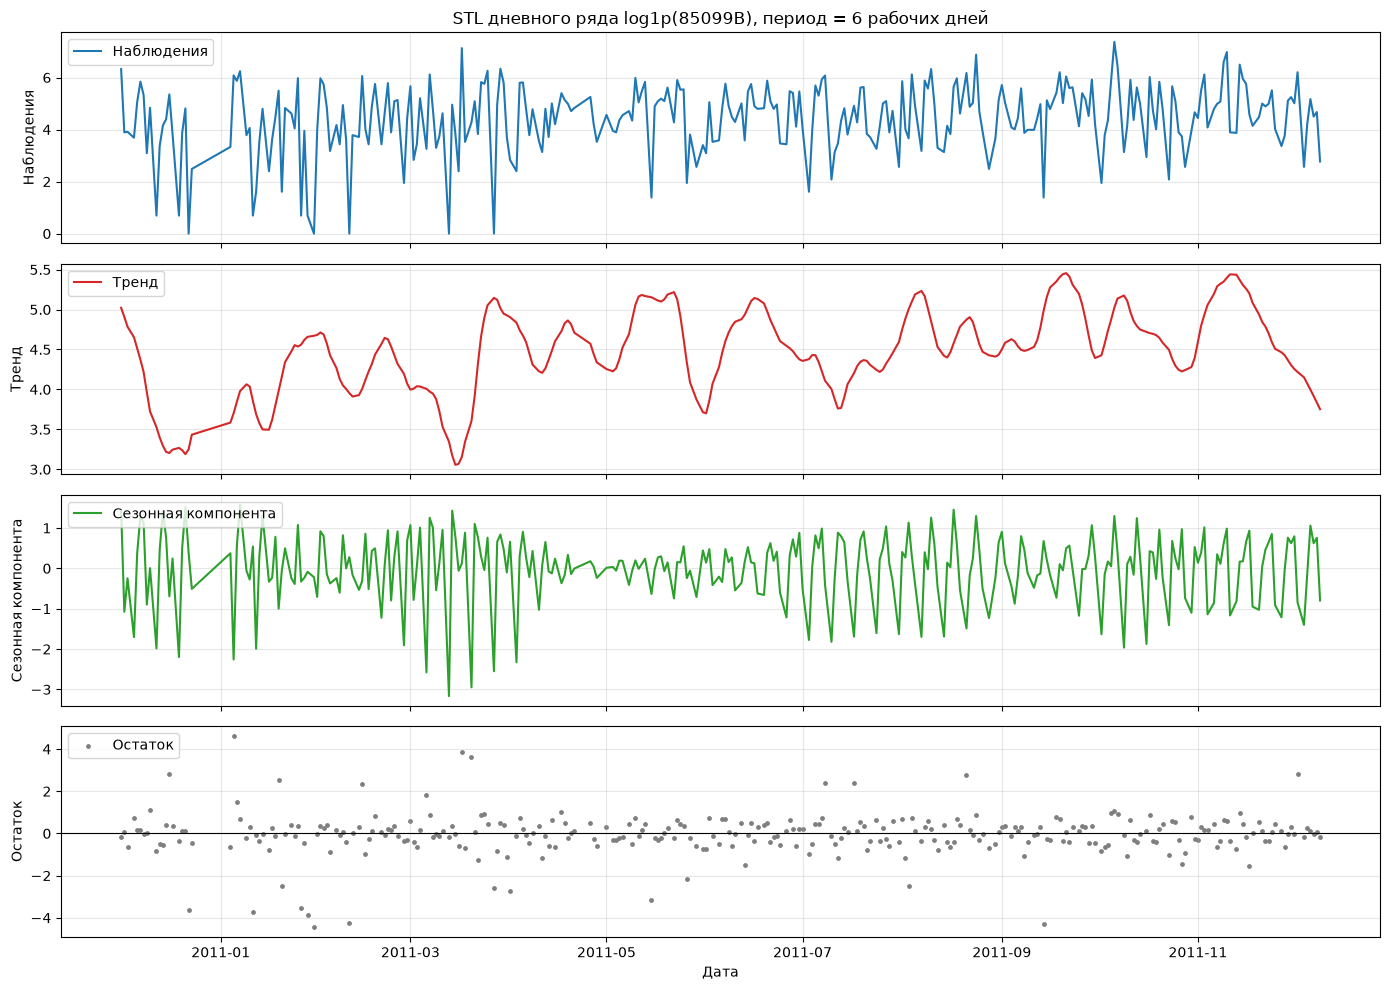

сила тренда F_T        0.167
сила сезонности F_S    0.316
dtype: float64

In [27]:
log_daily = ta.transform_series(series["D"], log=True)
stl_d, idx_d = ta.stl_decompose(log_daily, period=6)
ta.plot_stl(stl_d, idx_d, f"STL дневного ряда log1p({STOCK_CODE}), период = 6 рабочих дней")
ta.decomposition_strength(stl_d)

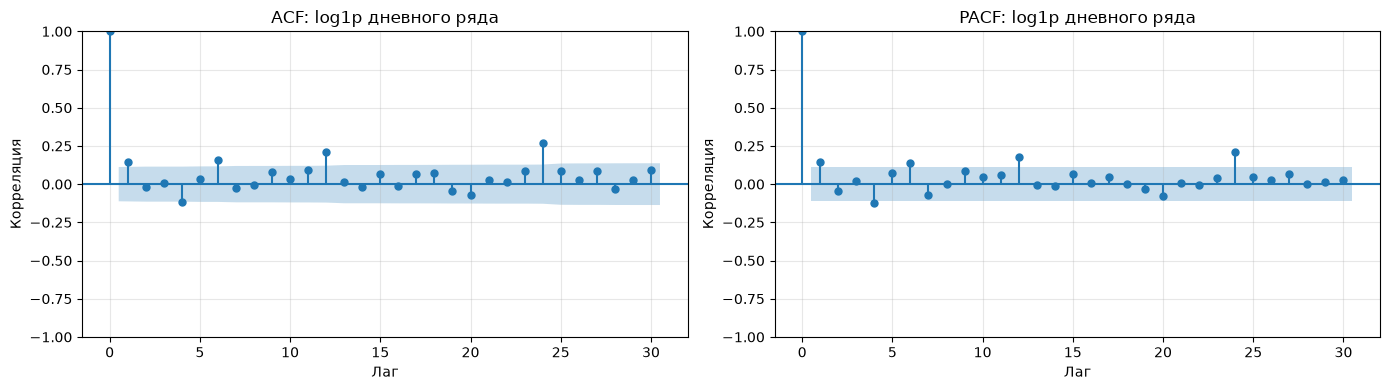

In [28]:
ta.plot_acf_pacf(log_daily, 30, 'log1p дневного ряда')

In [29]:
ta.seasonal_acf_check(log_daily, [1, 6, 12, 18, 24])

,acf,граница 95%,значимо
lag,,,
1,0.146,0.112,True
6,0.159,0.112,True
12,0.209,0.112,True
18,0.074,0.112,False
24,0.268,0.112,True


### 5.2. Недельный ряд, период 4 (гипотеза месячного цикла)

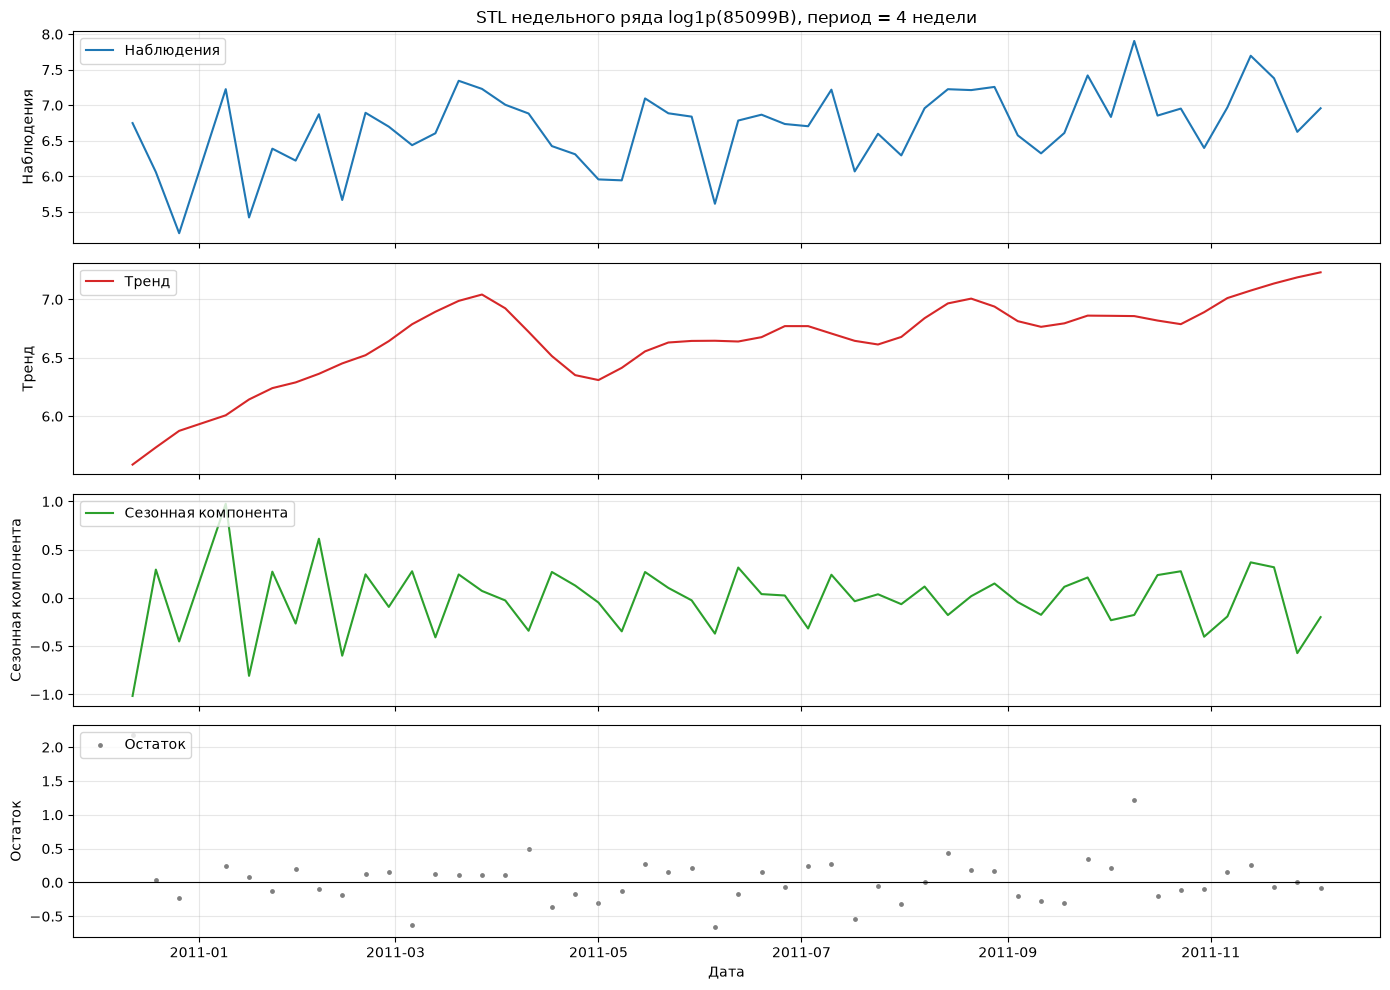

сила тренда F_T        0.260
сила сезонности F_S    0.156
dtype: float64

In [30]:
log_weekly = ta.transform_series(series["W"], log=True)
stl_w, idx_w = ta.stl_decompose(log_weekly, period=4)
ta.plot_stl(stl_w, idx_w, f"STL недельного ряда log1p({STOCK_CODE}), период = 4 недели")
ta.decomposition_strength(stl_w)

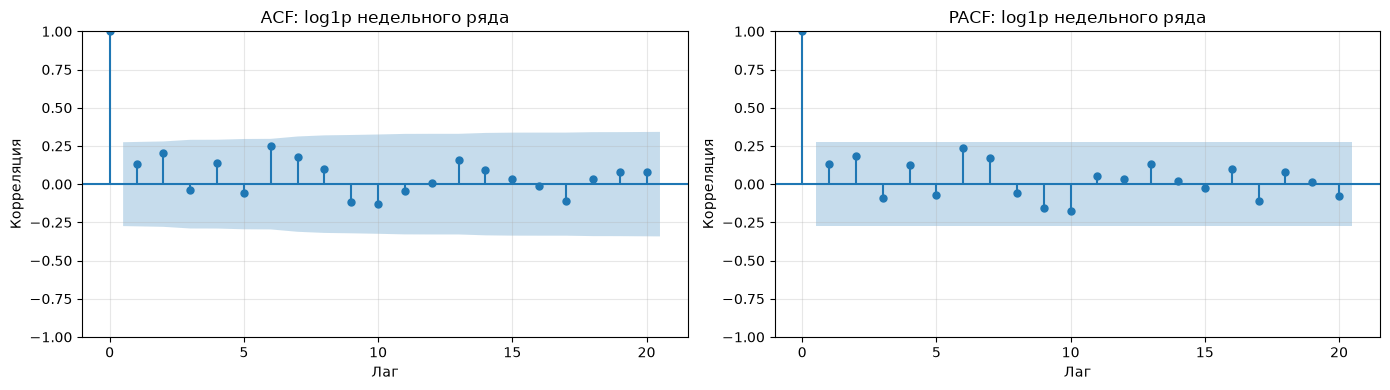

In [31]:
ta.plot_acf_pacf(log_weekly, 20, 'log1p недельного ряда')

In [32]:
ta.seasonal_acf_check(log_weekly, [1, 2, 4, 8, 12])

,acf,граница 95%,значимо
lag,,,
1,0.135,0.274,False
2,0.202,0.274,False
4,0.137,0.274,False
8,0.102,0.274,False
12,0.005,0.274,False


### 5.3. Месячный ряд: только тренд

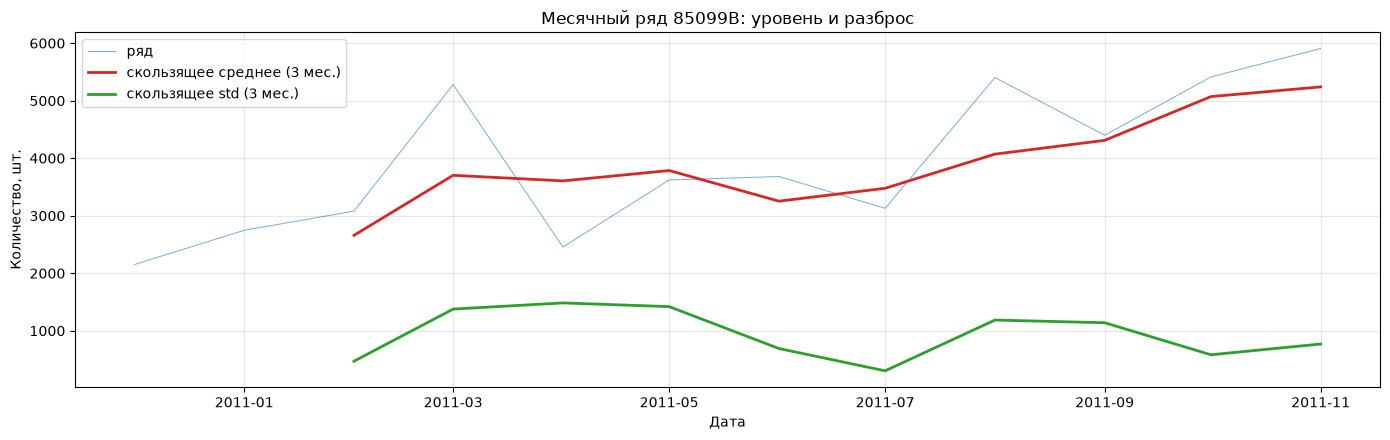

n                                 12.00000
Kendall tau                        0.69700
Mann–Kendall p-value               0.00097
наклон OLS за период             270.05000
OLS p-value                        0.00503
рост за период, % от среднего      6.86000
Name: quantity (месяц), dtype: float64

In [33]:
ta.plot_rolling(series["M"], 3, f"Месячный ряд {STOCK_CODE}: уровень и разброс", "мес.")
ta.trend_test(series["M"])

**Вывод о сезонности**
- **Дневной ряд:** **недельная сезонность есть, но слабая относительно шума.** Её подтверждают три независимых результата: значимые различия по дням недели (Kruskal–Wallis, п. 4.3), устойчивый сезонный профиль STL с провалом по воскресеньям и значимые пики ACF на лагах, кратных периоду (6, 12, 24). При этом сила сезонности F_S заметно ниже 0.64: основную часть дисперсии дневного ряда составляет остаток, то есть крупные нерегулярные заказы. Тренд-компонента показывает постепенный рост уровня во второй половине года.
- **Недельный ряд:** ACF на лагах 4, 8 и 12 незначима, сезонная компонента STL с периодом 4 мала и неустойчива. **Месячного цикла нет.** Основная структура недельного ряда состоит из тренда (F_T больше F_S) и шума.
- **Месячный ряд:** годовую сезонность **по имеющимся данным установить нельзя**, есть только один год наблюдений. Рост продаж осенью 2011 (август–ноябрь) может быть как предрождественской сезонностью, так и трендом. При 12 точках эти эффекты не разделить, поэтому сезонность не объявляем, а фиксируем **значимый восходящий тренд**.

## 6. Проверка стационарности

Используем два теста с противоположными нулевыми гипотезами:
- **ADF (Augmented Dickey–Fuller):** H0 — есть единичный корень, ряд нестационарен. При p < 0.05 ряд стационарен;
- **KPSS:** H0 — ряд стационарен вокруг константы, `c`. При p < 0.05 ряд нестационарен. Вариант `ct` проверяет стационарность вокруг линейного тренда и помогает отличить тренд-стационарный ряд от ряда с единичным корнем.

Ряд считаем стационарным, если **оба** теста указывают на стационарность. p-value KPSS ограничено таблицей: 0.01 означает ≤ 0.01, 0.1 означает ≥ 0.1.

Возможные преобразования:
- `log1p` стабилизирует дисперсию (разброс растёт с уровнем);
- удаление линейного тренда (остатки регрессии на время) подходит для тренд-стационарного ряда;
- первая разность подходит для ряда с единичным корнем. Для тренд-стационарного ряда она избыточна: признак передифференцирования — ACF на лаге 1 около −0.5;
- сезонная разность с лагом 6 убирает недельную сезонность дневного ряда.

Колонка `ACF lag 1` в таблицах нужна для контроля передифференцирования.

In [34]:
stat_d = ta.stationarity_pipeline(series["D"], {
    "log1p": dict(log=True),
    "log1p + удаление тренда": dict(log=True, detrend=True),
    "log1p + diff(1)": dict(log=True, diff=1),
    "log1p + удаление тренда + seasonal diff(6)": dict(log=True, detrend=True, seasonal_diff=6),
})
stat_d

,n,ADF stat,ADF p-value,KPSS(c) stat,KPSS(c) p-value,KPSS(ct) p-value,ACF lag 1,вывод
исходный,305,-12.402,0.0000,0.563,0.0275,0.1,0.161,тренд-стационарен (нестационарен по уровню)
log1p,305,-3.291,0.0153,1.353,0.0100,0.1,0.146,тренд-стационарен (нестационарен по уровню)
log1p + удаление тренда,305,-10.704,0.0000,0.082,0.1000,0.1,0.098,стационарен
log1p + diff(1),304,-10.877,0.0000,0.058,0.1000,0.1,-0.396,стационарен
log1p + удаление тренда + seasonal diff(6),299,-8.045,0.0000,0.017,0.1000,0.1,0.180,стационарен


In [35]:
stat_w = ta.stationarity_pipeline(series["W"], {
    "log1p": dict(log=True),
    "log1p + удаление тренда": dict(log=True, detrend=True),
    "log1p + diff(1)": dict(log=True, diff=1),
})
stat_w

,n,ADF stat,ADF p-value,KPSS(c) stat,KPSS(c) p-value,KPSS(ct) p-value,ACF lag 1,вывод
исходный,51,-5.851,0.0,0.664,0.0168,0.1,0.167,тренд-стационарен (нестационарен по уровню)
log1p,51,-6.033,0.0,0.685,0.0149,0.1,0.135,тренд-стационарен (нестационарен по уровню)
log1p + удаление тренда,51,-5.040,0.0,0.041,0.1000,0.1,-0.070,стационарен
log1p + diff(1),50,-5.680,0.0,0.081,0.1000,0.1,-0.536,стационарен


In [36]:
stat_m = ta.stationarity_pipeline(series["M"], {
    "log1p + удаление тренда": dict(log=True, detrend=True),
    "log1p + diff(1)": dict(log=True, diff=1),
})
stat_m

,n,ADF stat,ADF p-value,KPSS(c) stat,KPSS(c) p-value,KPSS(ct) p-value,ACF lag 1,вывод
исходный,12,1.163,0.9957,0.550,0.0305,0.1000,0.207,нестационарен
log1p + удаление тренда,12,-9.616,0.0000,0.184,0.1000,0.0218,-0.362,стационарен
log1p + diff(1),11,-4.722,0.0001,0.354,0.0968,0.0100,-0.640,стационарен


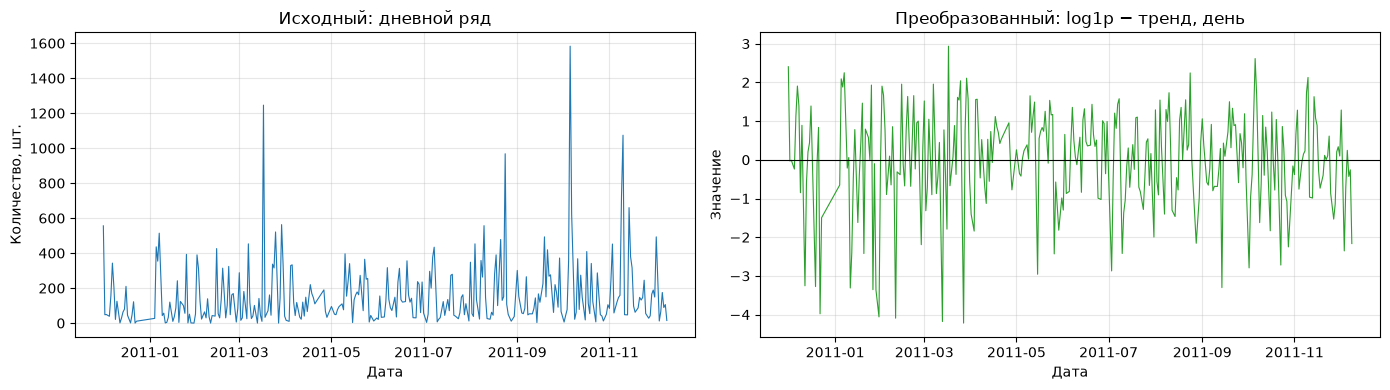

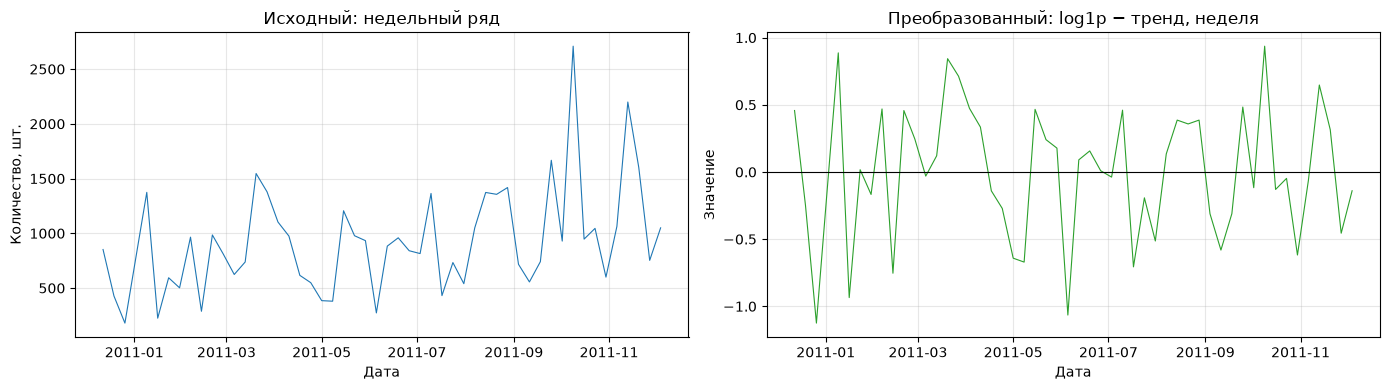

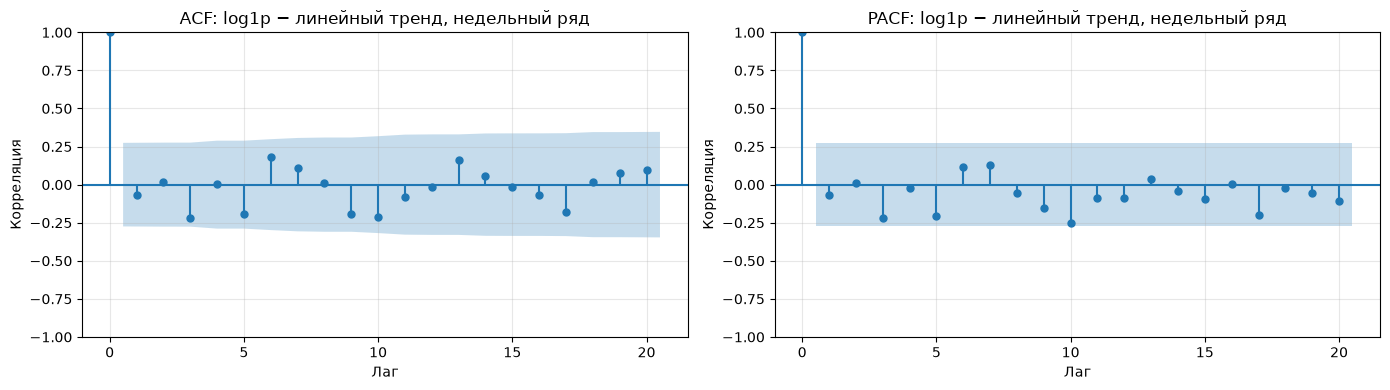

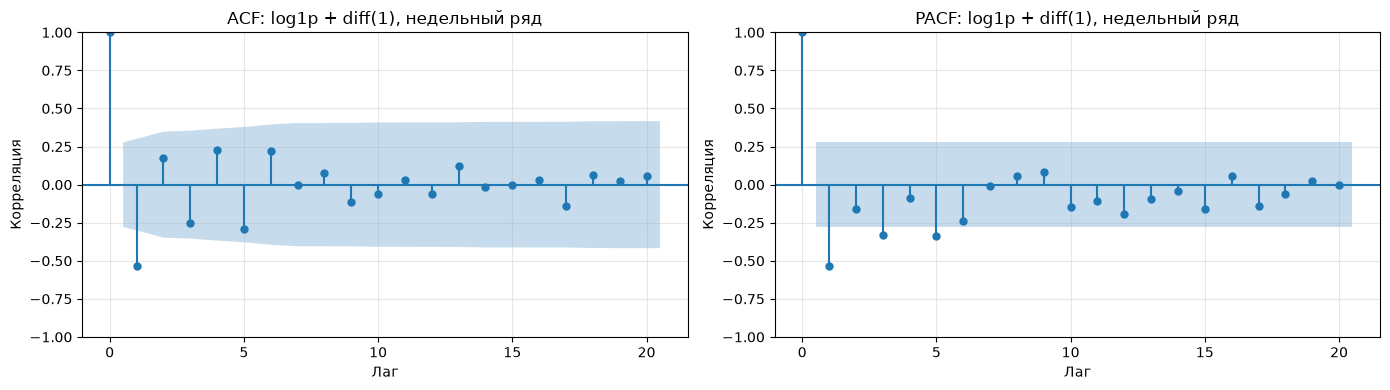

In [37]:
stationary_d = ta.transform_series(series["D"], log=True, detrend=True).rename("log1p − тренд, день")
stationary_w = ta.transform_series(series["W"], log=True, detrend=True).rename("log1p − тренд, неделя")
ta.plot_transformed(series["D"], stationary_d, "дневной ряд")
ta.plot_transformed(series["W"], stationary_w, "недельный ряд")
ta.plot_acf_pacf(stationary_w, 20, "log1p − линейный тренд, недельный ряд")
ta.plot_acf_pacf(ta.transform_series(series["W"], log=True, diff=1), 20, "log1p + diff(1), недельный ряд")

**Интерпретация**
- **Исходные дневной и недельный ряды.** ADF уверенно отвергает единичный корень (p < 0.001). KPSS(c) отвергает стационарность вокруг константы (p ≈ 0.02–0.03), а KPSS(ct) стационарность вокруг линейного тренда **не отвергает** (p ≥ 0.1). Вместе это значит, что ряд **нестационарен по уровню из-за детерминированного тренда, но тренд-стационарен**: единичного корня нет, колебания возвращаются к растущей линии тренда. Один `log1p` тренд не убирает, KPSS(c) по-прежнему отвергает стационарность.
- **`log1p` + удаление линейного тренда.** Все тесты согласованно показывают стационарность. Это преобразование соответствует природе ряда, поэтому выбираем его.
- **`log1p + diff(1)`** тоже даёт «стационарный» по тестам ряд, но ACF на лаге 1 становится сильно отрицательной (около −0.4…−0.5). Это классический признак **передифференцирования**: разность применена к ряду без единичного корня и добавляет искусственную MA-структуру. Поэтому дифференцирование здесь допустимо, но не оптимально.
- **Дневной ряд.** Дополнительная сезонная разность с лагом 6 после удаления тренда убирает недельный цикл. Это вариант для моделей без явной сезонной компоненты.
- **Месячный ряд (12 точек).** ADF не отвергает единичный корень, KPSS(c) отвергает стационарность, ряд нестационарен из-за сильного тренда. После преобразований тесты показывают стационарность, но **на 11–12 наблюдениях мощность тестов очень мала**, и вывод носит ориентировочный характер.
- **Итог:** для моделирования используем `log1p` и удаляем тренд, либо включаем тренд в модель как регрессор / drift. Для дневного ряда дополнительно нужно учесть недельную сезонность (период 6 рабочих дней): сезонной разностью или сезонной компонентой модели.

## 7. Итоговые выводы

| Этап | Результат |
|---|---|
| Данные | 85099B JUMBO BAG RED RETROSPOT, ≈48 тыс. шт. за 01.12.2010–09.12.2011; из анализа исключены отмены (≈2 % объёма), нулевые цены и дубликаты |
| Пропуски | 69 нерабочих дней (субботы, Рождество, банковские выходные) — структурные, оставлены `NaN` и исключены; 5 рабочих дней с 0 продаж — реальный нулевой спрос; неполные крайние недели/месяц исключены |
| Выбросы | ≈3 % дневных наблюдений — крупные оптовые заказы (до 1 200 шт.); не удалялись, влияние ограничено `robust` STL и `log1p` |
| Характеристики | дневной спрос erratic (CV > 1, асимметрия ≈3), недельный/месячный — smooth; значимый рост уровня; разброс растёт с уровнем; отрицательная связь цены и объёма (оптовые скидки) |
| Сезонность | недельная (период 6 рабочих дней) — есть, статистически значима, но слабая (воскресенья ниже); месячного цикла нет; годовую установить нельзя (1 год данных) |
| Стационарность | ADF + KPSS: исходные ряды нестационарны по уровню, но тренд-стационарны (единичного корня нет); стационарны после `log1p` + удаления линейного тренда; `diff(1)` тоже проходит тесты, но даёт передифференцирование (ACF₁ ≈ −0.4…−0.5) |